# 06 — Extrapolation des clusters CAH à la base Karafun

## Objectif et périmètre

Attribuer les groupes G1–G5 aux clients éligibles de la base source **sans réentraîner l’ACM ni recalculer la CAH**.

- **Partie A :** conserver les 20 000 étiquettes CAH et prédire les 48 218 autres clients de l’échantillon ACM.
- **Partie B :** projeter avec l’ACM enregistré les clients éligibles qui ne figurent pas dans l’échantillon ACM, puis leur appliquer le classifieur multinomial.

**Point de vigilance sur le dénominateur :** la source contient **341 092 lignes**, mais la préparation de `02_acm.ipynb` retire les clients ayant `methode_paiement == "Others"`. Les sorties originales indiquent **341 091 individus éligibles**. Le notebook vérifie cet écart : le client exclu reste présent dans la table finale avec un statut explicite et **sans cluster attribué**. Aucun groupe n’est inventé pour lui.

**Prérequis :** fichiers exportés par les notebooks 02, 03 et 05, configuration de recodification et fichier source original conservés dans le même ordre.

## 1. Configuration et chargement des artefacts

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().resolve()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
if not (RACINE / "src").is_dir():
    raise FileNotFoundError("Exécuter le notebook depuis la racine du dépôt ou le dossier notebooks/.")

import sys
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from src.classification_hierarchique import charger_coordonnees_et_identifiants
from src.classification_supervisee import NOMS_METIER_K5, charger_reference_cah

TAILLE_ACM_ATTENDUE = 68218
TAILLE_CAH_ATTENDUE = 20000
TAILLE_HORS_CAH_ATTENDUE = 48218
NOMBRE_AXES = 4
NOMBRE_GROUPES = 5
DOSSIER_SORTIE = RACINE / "resultats" / "extrapolation"

coordonnees, identifiants, metadonnees_acm = charger_coordonnees_et_identifiants(RACINE)
X_reference, y_reference, partitions, colonnes_axes, parametres_cah, _ = charger_reference_cah(
    RACINE, taille=TAILLE_CAH_ATTENDUE, axes=NOMBRE_AXES, graine=42, k=NOMBRE_GROUPES
)
chemin_modele = RACINE / "modeles" / "classifieur_clusters_k5.joblib"
chemin_metadonnees = RACINE / "modeles" / "classifieur_clusters_k5_metadonnees.json"
with chemin_metadonnees.open(encoding="utf-8") as fichier:
    metadonnees_classifieur = json.load(fichier)
modele = joblib.load(chemin_modele)

assert len(coordonnees) == len(identifiants) == TAILLE_ACM_ATTENDUE
assert len(partitions) == TAILLE_CAH_ATTENDUE
assert metadonnees_acm["iteration"] == 3
assert metadonnees_classifieur["modele_selectionne"] == "regression_logistique_multinomiale"
assert metadonnees_classifieur["nombre_axes"] == 4
assert metadonnees_classifieur["nombre_groupes"] == 5
assert metadonnees_classifieur["colonnes_axes"] == colonnes_axes
assert len(metadonnees_acm["variables_actives"]) == 10
assert len(metadonnees_acm["modalites_actives"]) == 42
assert np.array_equal(np.asarray(modele.classes_), np.arange(1, 6))
assert list(coordonnees.columns[:4]) == colonnes_axes
print(f"Échantillon ACM : {len(coordonnees):,} individus")
print(f"Partition CAH : {len(partitions):,} individus")
print(f"Classifieur retenu : {metadonnees_classifieur['modele_selectionne']}")

Échantillon ACM : 68,218 individus
Partition CAH : 20,000 individus
Classifieur retenu : regression_logistique_multinomiale


## 2. Correspondance et séparation sans ambiguïté

Les positions CAH correspondent aux **positions dans l’échantillon ACM**, non aux indices bruts. Les identifiants sont conservés et aucune jointure approximative n’est autorisée.

In [2]:
positions_cah = partitions["position_echantillon"].to_numpy(dtype=int)
assert len(np.unique(positions_cah)) == TAILLE_CAH_ATTENDUE
assert np.array_equal(
    identifiants.iloc[positions_cah]["position_echantillon"].to_numpy(), positions_cah
)

masque_cah = np.zeros(len(coordonnees), dtype=bool)
masque_cah[positions_cah] = True
positions_a_predire = np.flatnonzero(~masque_cah)
assert len(positions_a_predire) == TAILLE_HORS_CAH_ATTENDUE
assert len(np.intersect1d(positions_cah, positions_a_predire)) == 0
assert len(np.union1d(positions_cah, positions_a_predire)) == len(coordonnees)

colonnes_identification = list(identifiants.columns)
reference = identifiants.iloc[positions_cah].copy().reset_index(drop=True)
reference["groupe_k5"] = y_reference.to_numpy(dtype=int)
reference["origine_affectation"] = "CAH_reference"
reference["probabilite_max"] = np.nan
for groupe in range(1, 6):
    reference[f"probabilite_G{groupe}"] = np.nan

X_a_predire = coordonnees.iloc[positions_a_predire][colonnes_axes].copy()
assert X_a_predire.shape == (TAILLE_HORS_CAH_ATTENDUE, 4)
assert np.isfinite(X_a_predire.to_numpy(dtype=float)).all()
print("Correspondance validée ; lignes à prédire :", len(X_a_predire))

Correspondance validée ; lignes à prédire : 48218


## 3. Prédiction par la régression logistique multinomiale sauvegardée

Ici, seul `predict()` / `predict_proba()` est appelé : **aucun `fit()` n’est effectué**.

In [3]:
etiquettes_predites = np.asarray(modele.predict(X_a_predire), dtype=int)
probabilites = np.asarray(modele.predict_proba(X_a_predire), dtype=float)
assert probabilites.shape == (TAILLE_HORS_CAH_ATTENDUE, 5)
assert np.isfinite(probabilites).all()
assert np.allclose(probabilites.sum(axis=1), 1.0, atol=1e-8)
assert set(np.unique(etiquettes_predites)).issubset({1, 2, 3, 4, 5})
assert np.array_equal(etiquettes_predites, np.asarray(modele.classes_)[probabilites.argmax(axis=1)])

predictions = identifiants.iloc[positions_a_predire].copy().reset_index(drop=True)
predictions["groupe_k5"] = etiquettes_predites
predictions["origine_affectation"] = "regression_logistique_multinomiale"
predictions["probabilite_max"] = probabilites.max(axis=1)
for indice, groupe in enumerate(modele.classes_):
    predictions[f"probabilite_G{int(groupe)}"] = probabilites[:, indice]

reference["nom_segment"] = reference["groupe_k5"].map(NOMS_METIER_K5)
predictions["nom_segment"] = predictions["groupe_k5"].map(NOMS_METIER_K5)
assert reference["nom_segment"].notna().all()
assert predictions["nom_segment"].notna().all()
display(predictions.head())

,position_echantillon,id_anonyme,groupe_k5,origine_affectation,probabilite_max,probabilite_G1,probabilite_G2,probabilite_G3,probabilite_G4,probabilite_G5,nom_segment
0,1,73f52ec545df5ce3b1a3fd90abdd76ec5bd4137fe14bdd...,1,regression_logistique_multinomiale,0.994069,0.994069,0.005923,1.265931e-12,1.950195e-06,0.000006,Clients fidèles à forte valeur
1,2,9e40eee05b42e2d8c99ff8a972ff66f47db2614f7fc966...,4,regression_logistique_multinomiale,0.999581,0.000005,0.000402,2.228377e-08,9.995807e-01,0.000013,Clients intermédiaires souvent réactivés
2,3,0b8146f0a00c5cf4c3962373218cb5309a8f64b09ac645...,5,regression_logistique_multinomiale,0.999997,0.000002,0.000001,1.786441e-16,5.300161e-13,0.999997,Clients récents en phase d'intégration
3,4,0c049beaeada4fc987a933703e1a87e4d290fbf81d9343...,4,regression_logistique_multinomiale,0.997393,0.000007,0.000005,1.335325e-10,9.973935e-01,0.002595,Clients intermédiaires souvent réactivés
4,5,8b3c4e2bf6c0214e23f20e50026b56fb7418d69beb62f5...,2,regression_logistique_multinomiale,0.993660,0.004786,0.993660,1.850100e-07,1.257371e-04,0.001428,Clients en churn à faible fidélité


## 4. Fusion des 68 218 affectations et contrôles

In [4]:
colonnes_finales = (
    colonnes_identification + ["groupe_k5", "nom_segment", "origine_affectation", "probabilite_max"]
    + [f"probabilite_G{groupe}" for groupe in range(1, 6)]
)
base_acm_segmentee = pd.concat(
    [reference[colonnes_finales], predictions[colonnes_finales]],
    ignore_index=True,
).sort_values("position_echantillon", kind="stable").reset_index(drop=True)
assert len(base_acm_segmentee) == TAILLE_ACM_ATTENDUE
assert base_acm_segmentee["position_echantillon"].is_unique
assert np.array_equal(base_acm_segmentee["position_echantillon"], np.arange(TAILLE_ACM_ATTENDUE))
assert base_acm_segmentee["groupe_k5"].notna().all()
assert (base_acm_segmentee["origine_affectation"] == "CAH_reference").sum() == TAILLE_CAH_ATTENDUE
assert (base_acm_segmentee["origine_affectation"] == "regression_logistique_multinomiale").sum() == TAILLE_HORS_CAH_ATTENDUE
assert np.array_equal(base_acm_segmentee.iloc[positions_cah]["groupe_k5"].to_numpy(), y_reference.to_numpy())

bilan = (base_acm_segmentee.groupby(["origine_affectation", "groupe_k5", "nom_segment"])
         .size().rename("effectif").reset_index())
bilan["part_dans_origine_pct"] = 100 * bilan["effectif"] / bilan.groupby("origine_affectation")["effectif"].transform("sum")
display(bilan)
print("Clients segmentés dans l'échantillon ACM :", len(base_acm_segmentee))
print("Probabilité maximale médiane (prédictions) :", round(float(predictions["probabilite_max"].median()), 4))
print("Part des prédictions avec probabilité maximale < 0,60 :", round(float((predictions["probabilite_max"] < 0.60).mean() * 100), 2), "%")

,origine_affectation,groupe_k5,nom_segment,effectif,part_dans_origine_pct
0,CAH_reference,1,Clients fidèles à forte valeur,5134,25.670000
1,CAH_reference,2,Clients en churn à faible fidélité,4152,20.760000
2,CAH_reference,3,Clients sans activité observée,2201,11.005000
3,CAH_reference,4,Clients intermédiaires souvent réactivés,4060,20.300000
4,CAH_reference,5,Clients récents en phase d'intégration,4453,22.265000
5,regression_logistique_multinomiale,1,Clients fidèles à forte valeur,12735,26.411299
6,regression_logistique_multinomiale,2,Clients en churn à faible fidélité,10010,20.759882
7,regression_logistique_multinomiale,3,Clients sans activité observée,5374,11.145215
8,regression_logistique_multinomiale,4,Clients intermédiaires souvent réactivés,9546,19.797586
9,regression_logistique_multinomiale,5,Clients récents en phase d'intégration,10553,21.886018


Clients segmentés dans l'échantillon ACM : 68218
Probabilité maximale médiane (prédictions) : 0.9994
Part des prédictions avec probabilité maximale < 0,60 : 3.52 %


## 5. Export des résultats intermédiaires

In [5]:
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)
predictions.to_csv(DOSSIER_SORTIE / "clients_acm_hors_cah_predits.csv", index=False)
base_acm_segmentee.to_csv(DOSSIER_SORTIE / "echantillon_acm_segmente.csv", index=False)
bilan.to_csv(DOSSIER_SORTIE / "bilan_echantillon_acm.csv", index=False)
print("Exports intermédiaires enregistrés dans :", DOSSIER_SORTIE)

Exports intermédiaires enregistrés dans : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\resultats\extrapolation


## 6. Bilan intermédiaire — partie A

La partie A conserve les 20 000 affectations CAH de référence et classe les 48 218 autres clients de l'échantillon ACM avec la régression logistique multinomiale sauvegardée. Les sections suivantes étendent cette démarche aux **clients éligibles hors de l'échantillon ACM**.

La comparaison des distributions et des probabilités est descriptive ; elle ne mesure pas l'exactitude des prédictions sur les clients sans étiquette CAH.

## 7. Chargement et vérification de la base d'origine — partie B

Le notebook reconstitue **exactement** le tirage du notebook 02 (fraction 20 %, graine 42, après filtrage de `Others`) puis compare la correspondance source exportée. On ne suppose pas que la position dans l'échantillon ACM est l'indice dans le CSV brut.

Les lignes exclues par la préparation ne sont pas réintégrées artificiellement au modèle.

In [6]:
from src.preparation import charger_regroupements, preparer_donnees
from src.acm import appliquer_regroupements_experimentaux
from src.extrapolation_clusters import (
    verifier_correspondance_source,
    projeter_individus,
    predire_par_lots,
    verifier_couverture_finale,
)

CHEMIN_SOURCE = RACINE / "data" / "brutes" / "td_clustering_karafun.csv"
CHEMIN_ACM = RACINE / "modeles" / "acm_final.joblib"
CHEMIN_META_ACM = RACINE / "modeles" / "acm_final_metadonnees.json"
CHEMIN_CONFIG = RACINE / "config" / "regroupements.yaml"

for chemin in (CHEMIN_SOURCE, CHEMIN_ACM, CHEMIN_META_ACM, CHEMIN_CONFIG):
    if not chemin.is_file():
        raise FileNotFoundError(f"Prérequis absent : {chemin}")

donnees_brutes = pd.read_csv(CHEMIN_SOURCE)
if len(donnees_brutes) != 341092:
    raise ValueError(f"Nombre de lignes brutes inattendu : {len(donnees_brutes)}")
regroupements = charger_regroupements(CHEMIN_CONFIG)
donnees_preparees, donnees_nettoyees = preparer_donnees(donnees_brutes, regroupements)
if len(donnees_nettoyees) != 341091:
    raise ValueError(f"Nombre de clients éligibles inattendu : {len(donnees_nettoyees)}")

indices_echantillon = verifier_correspondance_source(
    donnees_brutes, donnees_nettoyees, identifiants, graine=42, fraction=0.20
)
indices_eligibles = donnees_nettoyees.index.to_numpy(dtype=int)
indices_hors_acm = np.setdiff1d(indices_eligibles, indices_echantillon)
indices_exclus = np.setdiff1d(np.arange(len(donnees_brutes)), indices_eligibles)
if len(indices_hors_acm) != 272873 or len(indices_exclus) != 1:
    raise ValueError("La répartition des clients hors ACM ou exclus est inattendue.")
if not (donnees_brutes.loc[indices_exclus, "methode_paiement"] == "Others").all():
    raise ValueError("Une exclusion n'est pas expliquée par la méthode de paiement Others.")

with CHEMIN_META_ACM.open(encoding="utf-8") as fichier:
    meta_acm_complete = json.load(fichier)
if meta_acm_complete != metadonnees_acm:
    raise ValueError("Les métadonnées ACM ne correspondent pas à celles chargées en partie A.")
if meta_acm_complete.get("graine") != 42 or meta_acm_complete.get("iteration") != 3:
    raise ValueError("L'ACM final attendu est l'itération 3 avec la graine 42.")
if meta_acm_complete.get("regroupements_acm_finaux") != {
    "avg_songs_sessions_rec": {
        "03_10_et_plus": ["03_Eleve_10_a_20", "04_Tres_eleve_20_et_plus"]
    }
}:
    raise ValueError("Les regroupements enregistrés ne correspondent pas à l'ACM final.")

modele_acm = joblib.load(CHEMIN_ACM)
variables_actives = meta_acm_complete["variables_actives"]
modalites_actives = meta_acm_complete["modalites_actives"]
if len(variables_actives) != 10 or len(modalites_actives) != 42:
    raise ValueError("Structure des variables ou modalités ACM inattendue.")

donnees_acm_finales = appliquer_regroupements_experimentaux(
    donnees_nettoyees, meta_acm_complete["regroupements_acm_finaux"]
)
print("Lignes source :", len(donnees_brutes))
print("Individus éligibles :", len(donnees_acm_finales))
print("Individus à projeter hors ACM :", len(indices_hors_acm))
print("Individus exclus (paiement Others) :", len(indices_exclus))

Lignes source : 341092
Individus éligibles : 341091
Individus à projeter hors ACM : 272873
Individus exclus (paiement Others) : 1


## 8. Contrôle indispensable de la projection ACM

Avant de projeter les clients hors échantillon, on réapplique `row_coordinates()` à **200 clients connus** et on compare leurs coordonnées aux valeurs déjà exportées par le notebook 02. Si cette vérification échoue, le traitement est interrompu : une simple proximité dans la distribution globale ne suffit pas à confirmer la compatibilité du modèle.

In [7]:
positions_test = np.unique(np.linspace(0, len(indices_echantillon) - 1, 200, dtype=int))
indices_test = indices_echantillon[positions_test]
coordonnees_recalculees = projeter_individus(
    modele_acm,
    donnees_acm_finales.loc[indices_test],
    variables_actives,
    modalites_actives,
    nombre_axes=NOMBRE_AXES,
    taille_lot=200,
)
coordonnees_attendues = coordonnees.iloc[positions_test, :NOMBRE_AXES].to_numpy(dtype=float)
coordonnees_observees = coordonnees_recalculees.to_numpy(dtype=float)
ecart_maximal = float(np.max(np.abs(coordonnees_attendues - coordonnees_observees)))
print(f"Écart maximal de reprojection sur les {len(indices_test)} individus tests : {ecart_maximal:.3e}")
if not np.allclose(coordonnees_attendues, coordonnees_observees, rtol=1e-5, atol=1e-5):
    raise ValueError(
        "Les coordonnées recalculées ne reproduisent pas l'ACM sauvegardée. "
        "Vérifier la source, les modalités, l'ordre des colonnes et la version de prince."
    )
print("Projection sur les individus connus : conforme.")

Écart maximal de reprojection sur les 200 individus tests : 5.551e-17
Projection sur les individus connus : conforme.


## 9. Projection et prédiction des clients éligibles hors ACM

Le tableau disjonctif utilise **strictement les 42 modalités sauvegardées**. Les nouvelles modalités inconnues ou les valeurs manquantes provoquent une erreur explicite : elles ne sont jamais converties silencieusement en modalités de référence.

Pour limiter l'utilisation de mémoire, les projections et prédictions sont réalisées par lots. **Aucun ajustement (`fit`) n'est lancé.**

In [8]:
TAILLE_LOT = 5000

donnees_hors_acm = donnees_acm_finales.loc[indices_hors_acm]
coordonnees_hors_acm = projeter_individus(
    modele_acm,
    donnees_hors_acm,
    variables_actives,
    modalites_actives,
    nombre_axes=NOMBRE_AXES,
    taille_lot=TAILLE_LOT,
)
coordonnees_hors_acm.columns = colonnes_axes
etiquettes_hors_acm, probabilites_hors_acm = predire_par_lots(
    modele, coordonnees_hors_acm, colonnes_axes, taille_lot=TAILLE_LOT
)

hors_acm_predits = pd.DataFrame({
    "indice_ligne_source": indices_hors_acm,
    "position_echantillon": pd.Series([pd.NA] * len(indices_hors_acm), dtype="Int64"),
    "groupe_k5": etiquettes_hors_acm,
    "origine_affectation": "projection_ACM_et_regression_logistique",
    "probabilite_max": probabilites_hors_acm.max(axis=1),
})
for indice, groupe in enumerate(modele.classes_):
    hors_acm_predits[f"probabilite_G{int(groupe)}"] = probabilites_hors_acm[:, indice]
hors_acm_predits["nom_segment"] = hors_acm_predits["groupe_k5"].map(NOMS_METIER_K5)
if hors_acm_predits["nom_segment"].isna().any():
    raise ValueError("Certaines prédictions ne possèdent pas de nom de segment.")
print("Clients hors ACM prédits :", len(hors_acm_predits))
display(hors_acm_predits.head())

Clients hors ACM prédits : 272873


,indice_ligne_source,position_echantillon,groupe_k5,origine_affectation,probabilite_max,probabilite_G1,probabilite_G2,probabilite_G3,probabilite_G4,probabilite_G5,nom_segment
0,1,<NA>,5,projection_ACM_et_regression_logistique,1.0,1.188884e-12,3.847376e-11,1.107979e-22,8.611028e-22,1.0,Clients récents en phase d'intégration
1,3,<NA>,5,projection_ACM_et_regression_logistique,1.0,4.750403e-11,1.632162e-10,1.251861e-21,9.735178e-20,1.0,Clients récents en phase d'intégration
2,4,<NA>,5,projection_ACM_et_regression_logistique,1.0,2.580105e-13,1.434622e-12,2.228546e-11,4.248058e-23,1.0,Clients récents en phase d'intégration
3,5,<NA>,5,projection_ACM_et_regression_logistique,1.0,1.743691e-12,2.054465e-11,1.756372e-23,5.143723e-20,1.0,Clients récents en phase d'intégration
4,8,<NA>,5,projection_ACM_et_regression_logistique,1.0,5.508855e-12,4.739677e-11,1.017486e-22,1.080994e-21,1.0,Clients récents en phase d'intégration


## 10. Constitution et contrôle de la table des 341 092 lignes sources

Les groupes CAH des 20 000 clients de référence sont conservés. Les 48 218 prédictions de la partie A sont conservées également. Les **272 873 clients éligibles hors ACM** reçoivent une prédiction à partir du modèle sauvegardé. La **ligne exclue par la préparation** reste dans le résultat sans cluster, pour respecter l'effectif brut et rendre la limite du dispositif visible.

In [9]:
# Correspondance reconstruite depuis l'ordre de l'échantillonnage du notebook 02.
base_acm_avec_source = base_acm_segmentee.copy()
base_acm_avec_source["indice_ligne_source"] = indices_echantillon[
    base_acm_avec_source["position_echantillon"].to_numpy(dtype=int)
]
if "indice_ligne_source" in base_acm_segmentee.columns and not np.array_equal(
    base_acm_segmentee["indice_ligne_source"].to_numpy(),
    base_acm_avec_source["indice_ligne_source"].to_numpy()
):
    raise ValueError("La correspondance des indices source de la partie A a changé.")

colonnes_sortie = [
    "indice_ligne_source", "position_echantillon", "groupe_k5", "nom_segment",
    "origine_affectation", "probabilite_max",
] + [f"probabilite_G{i}" for i in range(1, 6)]

exclus = pd.DataFrame({
    "indice_ligne_source": indices_exclus,
    "position_echantillon": pd.Series([pd.NA] * len(indices_exclus), dtype="Int64"),
    "groupe_k5": pd.Series([pd.NA] * len(indices_exclus), dtype="Int64"),
    "nom_segment": pd.Series([pd.NA] * len(indices_exclus), dtype="string"),
    "origine_affectation": "exclu_preparation",
    "probabilite_max": np.nan,
})
for indice in range(1, 6):
    exclus[f"probabilite_G{indice}"] = np.nan

base_complete_segmentee = pd.concat(
    [base_acm_avec_source[colonnes_sortie], hors_acm_predits[colonnes_sortie], exclus[colonnes_sortie]],
    ignore_index=True,
).sort_values("indice_ligne_source", kind="stable").reset_index(drop=True)
base_complete_segmentee["groupe_k5"] = base_complete_segmentee["groupe_k5"].astype("Int64")
base_complete_segmentee["position_echantillon"] = base_complete_segmentee["position_echantillon"].astype("Int64")

verifier_couverture_finale(
    base_complete_segmentee,
    nombre_brut=len(donnees_brutes),
    nombre_acm=len(coordonnees),
    nombre_hors_acm=len(indices_hors_acm),
    nombre_exclus=len(indices_exclus),
)

origines = base_complete_segmentee["origine_affectation"].value_counts().rename_axis(
    "origine_affectation"
).reset_index(name="effectif")
repartition_finale = (
    base_complete_segmentee.groupby(["groupe_k5", "nom_segment"], dropna=False)
    .size().rename("effectif").reset_index()
)
repartition_finale["pourcentage_source"] = 100 * repartition_finale["effectif"] / len(base_complete_segmentee)
print("Base source conservée :", len(base_complete_segmentee))
print("Clients affectés :", base_complete_segmentee["groupe_k5"].notna().sum())
print("Clients exclus sans groupe :", base_complete_segmentee["groupe_k5"].isna().sum())
display(origines)
display(repartition_finale)

Base source conservée : 341092
Clients affectés : 341091
Clients exclus sans groupe : 1


,origine_affectation,effectif
0,projection_ACM_et_regression_logistique,272873
1,regression_logistique_multinomiale,48218
2,CAH_reference,20000
3,exclu_preparation,1


,groupe_k5,nom_segment,effectif,pourcentage_source
0,1,Clients fidèles à forte valeur,89792,26.324863
1,2,Clients en churn à faible fidélité,71022,20.821948
2,3,Clients sans activité observée,37784,11.077363
3,4,Clients intermédiaires souvent réactivés,67755,19.864142
4,5,Clients récents en phase d'intégration,74738,21.911390
5,<NA>,<NA>,1,0.000293


## 11. Exports de la partie B et bilan final

Les exports distinguent les clients réellement classés des lignes exclues. La table finale a une ligne par enregistrement source. Les probabilités sont absentes pour les étiquettes CAH de référence et pour les exclusions, car aucune prédiction supervisée ne leur a été appliquée.

In [10]:
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)
hors_acm_predits.to_csv(DOSSIER_SORTIE / "clients_hors_acm_predits.csv", index=False)
base_complete_segmentee.to_csv(DOSSIER_SORTIE / "base_complete_segmentee.csv", index=False)
origines.to_csv(DOSSIER_SORTIE / "bilan_origines_base_complete.csv", index=False)
repartition_finale.to_csv(DOSSIER_SORTIE / "bilan_groupes_base_complete.csv", index=False)
print("Exports terminés dans :", DOSSIER_SORTIE)

Exports terminés dans : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\resultats\extrapolation


## 12. Comparaison des distributions — CAH et base complète

Les 20 000 clients de la CAH sont comparés aux **341 091 clients classés** de la base historique. L'enregistrement exclu de la préparation n'entre pas dans le dénominateur des proportions. Les barres expriment des **pourcentages**, et non des effectifs, pour rendre comparables les deux populations de tailles différentes.

Cette analyse vérifie la cohérence globale des répartitions, **sans constituer une mesure de précision individuelle** des prédictions.

,groupe_k5,nom_segment,effectif_CAH,part_CAH_pct,effectif_base_complete,part_base_complete_pct,ecart_points
0,1,Clients fidèles à forte valeur,5134,25.67,89792,26.32,0.65
1,2,Clients en churn à faible fidélité,4152,20.76,71022,20.82,0.06
2,3,Clients sans activité observée,2201,11.00,37784,11.08,0.07
3,4,Clients intermédiaires souvent réactivés,4060,20.30,67755,19.86,-0.44
4,5,Clients récents en phase d'intégration,4453,22.26,74738,21.91,-0.35


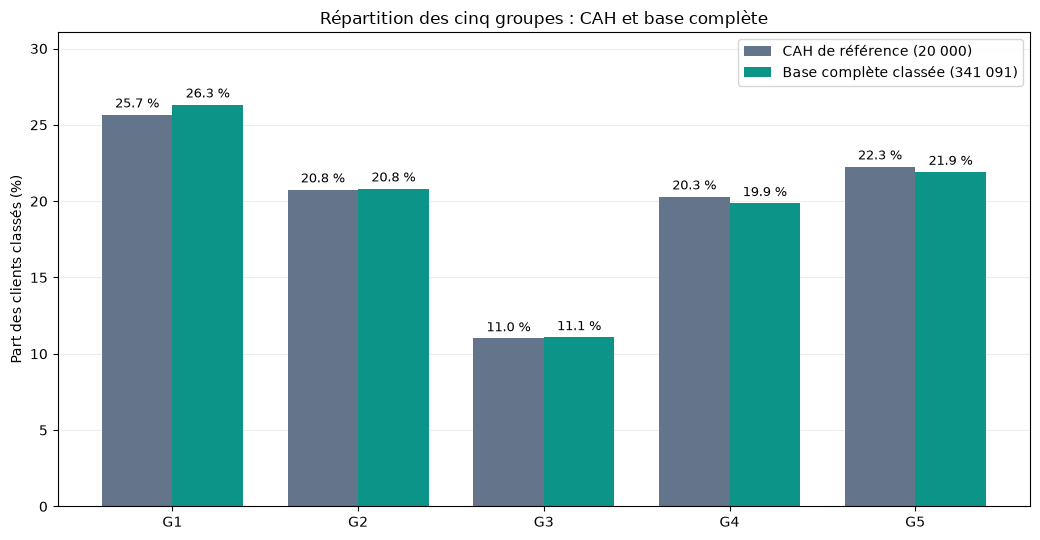

Écart maximal absolu : 0.65 point(s) de pourcentage


In [11]:
import matplotlib.pyplot as plt

GROUPES = np.arange(1, NOMBRE_GROUPES + 1)
COULEURS_GROUPES = {
    groupe: plt.get_cmap("tab10")(indice)
    for indice, groupe in enumerate(GROUPES)
}

comptes_cah = reference["groupe_k5"].value_counts().reindex(GROUPES, fill_value=0)
comptes_totaux = base_complete_segmentee["groupe_k5"].dropna().astype(int).value_counts().reindex(GROUPES, fill_value=0)
assert comptes_cah.sum() == TAILLE_CAH_ATTENDUE
assert comptes_totaux.sum() == len(base_complete_segmentee) - len(indices_exclus)

comparaison_repartition = pd.DataFrame({
    "groupe_k5": GROUPES,
    "nom_segment": [NOMS_METIER_K5[int(groupe)] for groupe in GROUPES],
    "effectif_CAH": comptes_cah.to_numpy(),
    "part_CAH_pct": 100 * comptes_cah.to_numpy() / comptes_cah.sum(),
    "effectif_base_complete": comptes_totaux.to_numpy(),
    "part_base_complete_pct": 100 * comptes_totaux.to_numpy() / comptes_totaux.sum(),
})
comparaison_repartition["ecart_points"] = (
    comparaison_repartition["part_base_complete_pct"]
    - comparaison_repartition["part_CAH_pct"]
)
display(comparaison_repartition.round(2))

positions = np.arange(NOMBRE_GROUPES)
largeur = 0.38
fig, ax = plt.subplots(figsize=(10.5, 5.5))
barres_cah = ax.bar(
    positions - largeur / 2, comparaison_repartition["part_CAH_pct"],
    largeur, color="#64748b", label="CAH de référence (20 000)"
)
barres_total = ax.bar(
    positions + largeur / 2, comparaison_repartition["part_base_complete_pct"],
    largeur, color="#0d9488", label="Base complète classée (341 091)"
)
for barres in (barres_cah, barres_total):
    ax.bar_label(barres, fmt="%.1f %%", padding=3, fontsize=9)
ax.set_xticks(positions, [f"G{groupe}" for groupe in GROUPES])
ax.set_ylabel("Part des clients classés (%)")
ax.set_title("Répartition des cinq groupes : CAH et base complète")
ax.set_ylim(0, max(comparaison_repartition[["part_CAH_pct", "part_base_complete_pct"]].max()) * 1.18)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.22)
ax.set_axisbelow(True)
fig.tight_layout()
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)
fig.savefig(DOSSIER_SORTIE / "comparaison_repartition_CAH_base_complete.png", dpi=170, bbox_inches="tight")
plt.show()

print(
    "Écart maximal absolu :",
    f"{comparaison_repartition['ecart_points'].abs().max():.2f} point(s) de pourcentage"
)


## 13. Représentation factorielle — centres et ellipses de dispersion

Les groupes ont été établis par Ward dans un espace à **quatre axes ACM**. Pour examiner leur position dans la base complète, nous représentons deux plans : **axes 1–2** et **axes 1–3**.

- Les **centres** et les **ellipses de covariance** sont calculés sur **l'ensemble des 341 091 clients classés** ; l'individu exclu n'est pas représenté.
- Les points affichés ne forment qu'un **échantillon reproductible de 250 individus par groupe** pour éviter la surcharge visuelle.
- Chaque ellipse est définie par une distance de **1,5 écart-type multivarié** autour du centre, dans le plan concerné. Il s'agit d'une **dispersion descriptive**, ni d'un intervalle de confiance du centre, ni d'une frontière de classification, ni d'une région contenant nécessairement une proportion fixe de clients.
- Un éventuel recouvrement sur deux axes n'implique pas que les groupes se confondent dans l'espace complet à quatre dimensions.

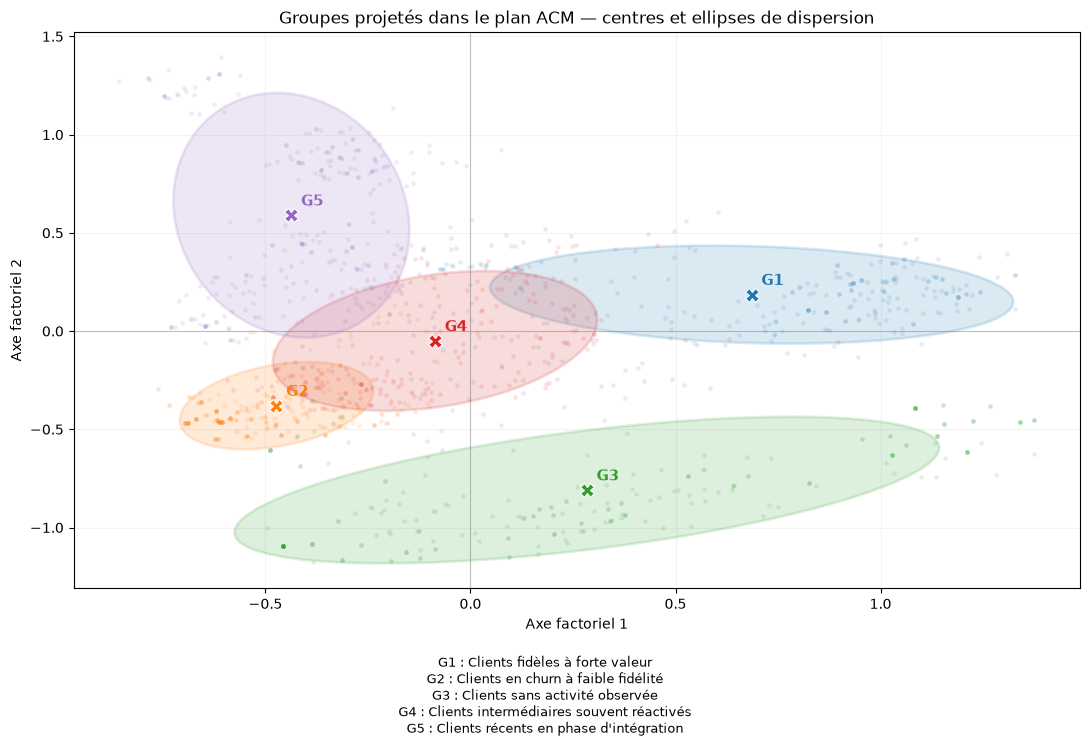

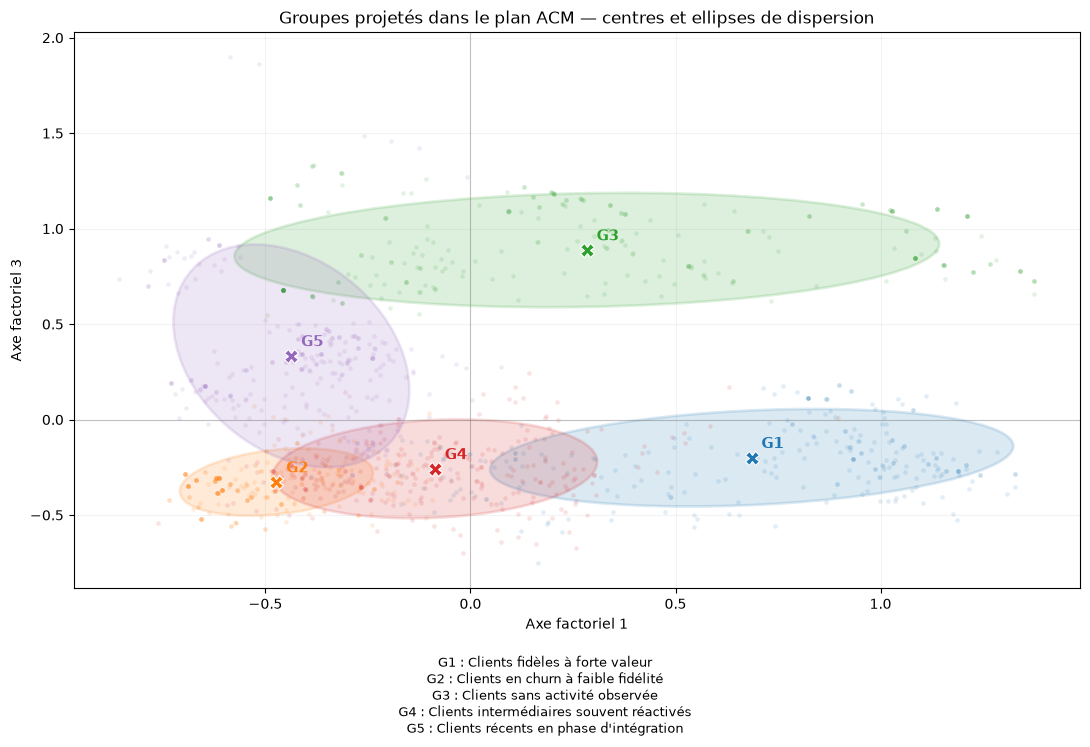

In [12]:
from matplotlib.patches import Ellipse

# Assemblage des coordonnées dans l'ordre du fichier source, contrôlé par les indices.
# Les coordonnées existantes et les coordonnées projetées restent inchangées.
coordonnees_completes = np.full((len(donnees_brutes), NOMBRE_AXES), np.nan, dtype=float)
indices_deja_acm = np.asarray(indices_echantillon, dtype=int)
indices_nouveaux = np.asarray(indices_hors_acm, dtype=int)
assert len(np.intersect1d(indices_deja_acm, indices_nouveaux)) == 0
coordonnees_completes[indices_deja_acm] = coordonnees[colonnes_axes].to_numpy(dtype=float)
coordonnees_completes[indices_nouveaux] = coordonnees_hors_acm[colonnes_axes].to_numpy(dtype=float)

etiquettes_completes = base_complete_segmentee["groupe_k5"].to_numpy(dtype=float, na_value=np.nan)
masque_classifies = np.isfinite(etiquettes_completes)
assert np.array_equal(
    base_complete_segmentee["indice_ligne_source"].to_numpy(dtype=int),
    np.arange(len(donnees_brutes)),
)
assert np.isfinite(coordonnees_completes[masque_classifies]).all()
assert np.isnan(coordonnees_completes[~masque_classifies]).all()
assert masque_classifies.sum() == 341091

# Contrôle : les étiquettes CAH de référence sont conservées à leur position source.
assert np.array_equal(
    etiquettes_completes[indices_deja_acm[positions_cah]].astype(int),
    y_reference.to_numpy(dtype=int),
)

GENERATEUR = np.random.default_rng(42)
indices_points = []
for groupe in GROUPES:
    indices_du_groupe = np.flatnonzero(etiquettes_completes == groupe)
    indices_points.append(GENERATEUR.choice(
        indices_du_groupe, size=min(250, len(indices_du_groupe)), replace=False
    ))

def tracer_plan_factoriel(axe_horizontal: int, axe_vertical: int) -> None:
    """Affiche les centres et ellipses de covariance des groupes sur deux axes ACM."""
    fig, ax = plt.subplots(figsize=(11, 7.5))
    for indice, groupe in enumerate(GROUPES):
        couleur = COULEURS_GROUPES[int(groupe)]
        masque = etiquettes_completes == groupe
        points = coordonnees_completes[masque][:, [axe_horizontal, axe_vertical]]
        centre = points.mean(axis=0)
        covariance = np.cov(points, rowvar=False)
        valeurs, vecteurs = np.linalg.eigh(covariance)
        ordre = np.argsort(valeurs)[::-1]
        valeurs = np.clip(valeurs[ordre], 0, None)
        vecteur_principal = vecteurs[:, ordre[0]]
        orientation = np.degrees(np.arctan2(vecteur_principal[1], vecteur_principal[0]))
        demi_axes = 1.5 * np.sqrt(valeurs)

        # Seuls les points dessinés sont échantillonnés ; le calcul de covariance est exhaustif.
        ech = coordonnees_completes[indices_points[indice]][:, [axe_horizontal, axe_vertical]]
        ax.scatter(ech[:, 0], ech[:, 1], s=11, alpha=0.13, color=couleur, linewidths=0)
        ellipse = Ellipse(
            xy=centre, width=2 * demi_axes[0], height=2 * demi_axes[1],
            angle=orientation, facecolor=couleur, edgecolor=couleur,
            linewidth=2, alpha=0.16,
        )
        ax.add_patch(ellipse)
        ax.plot(centre[0], centre[1], marker="X", markersize=10, color=couleur,
                markeredgecolor="white", markeredgewidth=0.8)
        ax.annotate(f"G{groupe}", xy=centre, xytext=(7, 7),
                    textcoords="offset points", fontsize=11, weight="bold", color=couleur)

    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.45)
    ax.axvline(0, color="gray", linewidth=0.8, alpha=0.45)
    ax.set_xlabel(f"Axe factoriel {axe_horizontal + 1}")
    ax.set_ylabel(f"Axe factoriel {axe_vertical + 1}")
    ax.set_title("Groupes projetés dans le plan ACM — centres et ellipses de dispersion")
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)
    # Légende lisible sans répéter les longues dénominations métier sur le tracé.
    legende = "\n".join(f"G{g} : {NOMS_METIER_K5[int(g)]}" for g in GROUPES)
    fig.text(0.5, 0.01, legende, ha="center", va="bottom", fontsize=9)
    fig.tight_layout(rect=[0, 0.13, 1, 1])
    fig.savefig(
        DOSSIER_SORTIE / f"ellipses_ACM_axes_{axe_horizontal + 1}_{axe_vertical + 1}.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()

tracer_plan_factoriel(0, 1)
tracer_plan_factoriel(0, 2)


## 14. Conclusion définitive de l'étape 3

L'extrapolation des cinq groupes de la CAH à la base historique Karafun est **achevée**. Le fichier d'origine compte **341 092 enregistrements**, dont **341 091 clients affectés à G1–G5** :

- **20 000** clients conservent leur étiquette issue de la CAH de référence ;
- **48 218** clients supplémentaires de l'échantillon ACM ont été classés à partir de leurs coordonnées existantes ;
- **272 873** clients hors échantillon ont été projetés sur les quatre axes de l'ACM sauvegardée, puis affectés par la régression logistique multinomiale ;
- **1** enregistrement, exclu de la préparation initiale (`methode_paiement == "Others"`), est conservé sans étiquette, avec le statut `exclu_preparation`.

La reprojection de **200 individus connus** a produit un écart maximal de **5,551 × 10⁻¹⁷** par rapport aux coordonnées ACM de référence, confirmant la concordance numérique de la projection sur ce contrôle.

La répartition finale parmi les **341 091 clients classés** demeure très proche de celle des **20 000 clients CAH**. Les groupes G1 à G5 représentent respectivement environ **26,32 %**, **20,82 %**, **11,08 %**, **19,86 %** et **21,91 %** de l'ensemble classé. Les graphiques de comparaison et les représentations factorielles permettent de décrire cette cohérence globale et la dispersion des segments dans certains plans ACM.

**Ces observations ne constituent pas une validation individuelle des prédictions.** Les affectations hors CAH ne disposent pas d'étiquettes de référence indépendantes ; les probabilités de la régression logistique n'ont pas été calibrées sur ces nouveaux clients. Les ellipses sont descriptives et ne représentent pas les frontières de Ward, construites en quatre dimensions.

**Aucun ajustement supplémentaire de l'ACM ni nouveau calcul de la CAH n'a été nécessaire.** Le processus s'appuie exclusivement sur les règles de préparation et les modèles enregistrés. La base exportée conserve également l'origine de chaque affectation et les probabilités des clients prédits.

**Prochaine étape :** construire l'application Streamlit en réutilisant cette chaîne de préparation, de projection et de prédiction pour les clients nouveaux ou mis à jour, en prévoyant une gestion explicite des modalités inconnues et des cas non éligibles.